# ME256 Homework 1: constrained optimization and a minimum-fence problem

**Assignment statement:** [ME256 Homework 1 (2011)](https://mecheng.iisc.ac.in/suresh/me256/hw2011/homework1.html). This notebook contains a runnable Python study of the reciprocal-objective and river-fence models.

## Problem 1 — reciprocal objective

Minimize

$$f(x_1,x_2)=\frac{5}{x_1}+\frac{2}{x_2}$$

subject to $x_1+x_2\le 3$, $4x_1+x_2\le 6$, $x_1+3x_2\le20$, and $x_1,x_2>0$. The cell solves from three starting points, plots the feasible region and iteration paths, and reports constraint slack.

At the solution, the second linear constraint is active and the other displayed linear constraints are slack. Restricting stationarity to $4x_1+x_2=6$ gives

$$-\frac{5}{x_1^2}+\frac{8}{y^2}=0,\qquad 4x_1+y=6,$$

so $y/x_1=\sqrt{8/5}$ and $x_1\approx1.13962$, $x_2\approx1.44152$. The objective is strictly convex on the positive quadrant, so this feasible stationary point is the unique global minimizer.

## Problem 2 — fixed-area river fence

Approximate the fence by $n=50$ segments with heights $y_0,\dots,y_n$ and horizontal endpoints $x_l,x_r$. Minimize the polygonal length

$$\sum_{j=0}^{n-1}\sqrt{(y_{j+1}-y_j)^2+\left(\frac{x_r-x_l}{n}\right)^2}$$

subject to the trapezoidal area being 25 m$^2$, nonnegative heights, and the fence staying below the river $y=8-0.8x$.

The endpoint condition from the discrete model is $x_l y_0=0$, a union of two branches ($x_l=0$ or $y_0=0$). The notebook solves both branches separately and compares their feasible results, avoiding a product equality with a degenerate gradient. This preserves the same endpoint alternatives and area/length model.

## Reproduction

Run the cells with Python 3 and the packages NumPy, SciPy, and Matplotlib. The remaining assignment questions are presented as prompts for additional derivation and sensitivity analysis.

## Reciprocal objective: numerical solve and iteration paths

The feasible polygon has vertices $(0,0)$, $(1.5,0)$, $(1,2)$, and $(0,3)$. The third linear inequality is satisfied throughout this polygon and is retained in the numerical constraints.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize


In [2]:
def reciprocal_objective(design):
    return 5.0 / design[0] + 2.0 / design[1]


def reciprocal_gradient(design):
    return np.array([-5.0 / design[0] ** 2, -2.0 / design[1] ** 2])


linear_matrix = np.array([[1.0, 1.0], [4.0, 1.0], [1.0, 3.0]])
linear_limits = np.array([3.0, 6.0, 20.0])
iteration_paths = []
reciprocal_results = []

for start in ([4.0, 1.0], [1.0, 4.0], [4.0, 4.0]):
    path = []
    result = minimize(
        reciprocal_objective,
        np.asarray(start),
        jac=reciprocal_gradient,
        method="SLSQP",
        bounds=[(1e-8, None), (1e-8, None)],
        constraints={
            "type": "ineq",
            "fun": lambda design: linear_limits - linear_matrix @ design,
            "jac": lambda design: -linear_matrix,
        },
        callback=lambda design: path.append(design.copy()),
        options={"maxiter": 500, "ftol": 1e-12},
    )
    if not result.success:
        raise RuntimeError(f"Reciprocal problem from {start} failed: {result.message}")
    reciprocal_results.append(result)
    iteration_paths.append(path)
    print(
        f"start={start}; converged={result.success}; "
        f"x=({result.x[0]:.6f}, {result.x[1]:.6f}); "
        f"objective={result.fun:.6f}; iterations={result.nit}"
    )

optimum = reciprocal_results[0].x
active_slack = linear_limits - linear_matrix @ optimum
print(f"constraint slacks={active_slack}")


start=[4.0, 1.0]; converged=True; x=(1.139620, 1.441518); objective=5.774852; iterations=7
start=[1.0, 4.0]; converged=True; x=(1.139620, 1.441518); objective=5.774852; iterations=8
start=[4.0, 4.0]; converged=True; x=(1.139620, 1.441518); objective=5.774852; iterations=8
constraint slacks=[ 4.18861165e-01 -5.50670620e-14  1.45358243e+01]


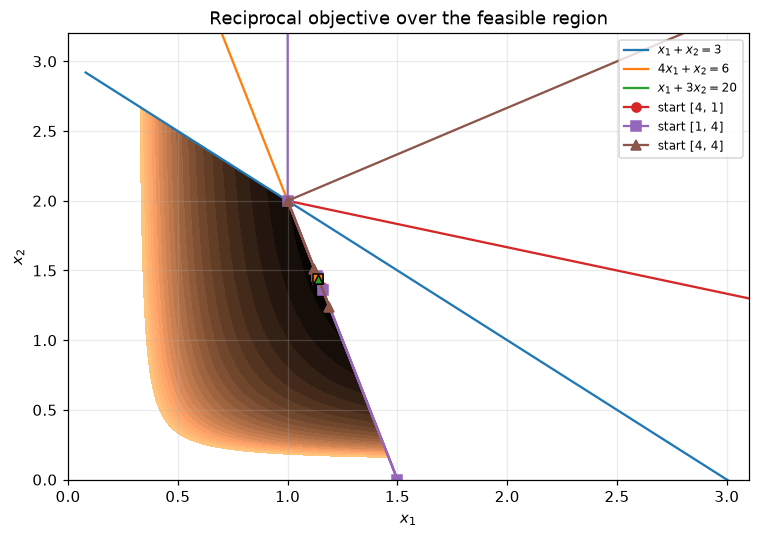

In [3]:
x_values = np.linspace(0.08, 3.1, 320)
y_values = np.linspace(0.08, 3.2, 320)
grid_x, grid_y = np.meshgrid(x_values, y_values)
grid_objective = 5.0 / grid_x + 2.0 / grid_y
feasible = (
    (grid_x + grid_y <= 3.0)
    & (4.0 * grid_x + grid_y <= 6.0)
    & (grid_x + 3.0 * grid_y <= 20.0)
)
figure, axes = plt.subplots(figsize=(7, 5))
axes.contourf(
    grid_x,
    grid_y,
    np.where(feasible, grid_objective, np.nan),
    levels=np.linspace(5.5, 16.0, 22),
    cmap="copper",
)
axes.plot(x_values, 3.0 - x_values, label=r"$x_1+x_2=3$")
axes.plot(x_values, 6.0 - 4.0 * x_values, label=r"$4x_1+x_2=6$")
axes.plot(x_values, (20.0 - x_values) / 3.0, label=r"$x_1+3x_2=20$")
markers = ["o", "s", "^"]
for start, path, result, marker in zip(
    ([4, 1], [1, 4], [4, 4]), iteration_paths, reciprocal_results, markers
):
    if path:
        path_values = np.vstack((start, path, result.x))
        axes.plot(path_values[:, 0], path_values[:, 1], marker + "-", label=f"start {start}")
    axes.scatter(*result.x, marker=marker, edgecolor="black", zorder=4)
axes.set(
    xlim=(0, 3.1),
    ylim=(0, 3.2),
    xlabel=r"$x_1$",
    ylabel=r"$x_2$",
    title="Reciprocal objective over the feasible region",
)
axes.grid(True, alpha=0.25)
axes.legend(fontsize=8, loc="upper right")
figure.tight_layout()
plt.show()


## River fence: discretized constrained solve

The area equality is the composite trapezoidal rule. Each ordinate is also bounded above by the river height at its linearly spaced horizontal coordinate. The two endpoint branches are solved independently, and the shorter feasible fence is selected.

In [4]:
def solve_fence_endpoint_branch(segment_count, target_area, fixed_endpoint):
    river_span = 10.0
    river_intercept = 8.0
    river_slope = river_intercept / river_span
    fractions = np.linspace(0.0, 1.0, segment_count + 1)
    initial = np.r_[np.ones(segment_count + 1), 8.0, 2.0]
    bounds = [(0.0, None)] * (segment_count + 1) + [
        (0.0, river_span),
        (0.0, river_span),
    ]

    if fixed_endpoint == "left coordinate":
        initial[-1] = 0.0
        bounds[-1] = (0.0, 0.0)
    elif fixed_endpoint == "initial height":
        initial[0] = 0.0
        bounds[0] = (0.0, 0.0)
    else:
        raise ValueError(f"Unknown endpoint branch: {fixed_endpoint}")

    def unpack(design):
        return design[: segment_count + 1], design[-2], design[-1]

    def objective(design):
        heights, right_x, left_x = unpack(design)
        horizontal_step = (right_x - left_x) / segment_count
        return np.sum(np.hypot(np.diff(heights), horizontal_step))

    def objective_jacobian(design):
        heights, right_x, left_x = unpack(design)
        horizontal_step = (right_x - left_x) / segment_count
        vertical_steps = np.diff(heights)
        segment_lengths = np.hypot(vertical_steps, horizontal_step)
        vertical_gradient = vertical_steps / segment_lengths
        gradient = np.zeros(segment_count + 3)
        gradient[: segment_count + 1] = np.r_[
            -vertical_gradient[0],
            vertical_gradient[:-1] - vertical_gradient[1:],
            vertical_gradient[-1],
        ]
        gradient[-2] = np.sum(horizontal_step / (segment_count * segment_lengths))
        gradient[-1] = -gradient[-2]
        return gradient

    def area_residual(design):
        heights, right_x, left_x = unpack(design)
        average_height_sum = (
            0.5 * heights[0] + np.sum(heights[1:-1]) + 0.5 * heights[-1]
        )
        return average_height_sum * (right_x - left_x) / segment_count - target_area

    def area_jacobian(design):
        heights, right_x, left_x = unpack(design)
        horizontal_step = (right_x - left_x) / segment_count
        average_height_sum = (
            0.5 * heights[0] + np.sum(heights[1:-1]) + 0.5 * heights[-1]
        )
        return np.r_[
            horizontal_step * np.r_[0.5, np.ones(segment_count - 1), 0.5],
            average_height_sum / segment_count,
            -average_height_sum / segment_count,
        ]

    def river_clearance(design):
        heights, right_x, left_x = unpack(design)
        horizontal_coordinates = left_x + fractions * (right_x - left_x)
        return river_intercept - river_slope * horizontal_coordinates - heights

    def river_jacobian(design):
        jacobian = np.zeros((segment_count + 1, segment_count + 3))
        jacobian[np.arange(segment_count + 1), np.arange(segment_count + 1)] = -1.0
        jacobian[:, -2] = -river_slope * fractions
        jacobian[:, -1] = -river_slope * (1.0 - fractions)
        return jacobian

    result = minimize(
        objective,
        initial,
        jac=objective_jacobian,
        method="SLSQP",
        bounds=bounds,
        constraints=[
            {"type": "eq", "fun": area_residual, "jac": area_jacobian},
            {"type": "ineq", "fun": river_clearance, "jac": river_jacobian},
        ],
        options={"maxiter": 1000, "ftol": 1e-11},
    )
    if not result.success:
        raise RuntimeError(f"Fence branch {fixed_endpoint} failed: {result.message}")
    return result, river_clearance(result.x), area_residual(result.x)


segment_count = 50
target_area = 25.0
fence_branches = [
    solve_fence_endpoint_branch(segment_count, target_area, branch)
    for branch in ("left coordinate", "initial height")
]
fence_result, river_clearance_values, area_error = min(
    fence_branches, key=lambda branch: branch[0].fun
)
fence_heights = fence_result.x[: segment_count + 1]
fence_right_x, fence_left_x = fence_result.x[-2:]
fence_x_coordinates = np.linspace(fence_left_x, fence_right_x, segment_count + 1)
print(f"segments={segment_count}; target area={target_area:.1f} m^2")
for branch, (result, clearances, area_residual) in zip(
    ("left coordinate fixed at zero", "initial height fixed at zero"), fence_branches
):
    print(
        f"{branch}: converged={result.success}; fence length={result.fun:.6f} m; "
        f"area error={area_residual:.3e} m^2; river clearance={min(clearances):.3e} m"
    )
print(
    f"selected: x_left={fence_left_x:.6f} m; x_right={fence_right_x:.6f} m; "
    f"maximum river clearance={max(river_clearance_values):.6f} m"
)


segments=50; target area=25.0 m^2
left coordinate fixed at zero: converged=True; fence length=4.728080 m; area error=-1.066e-14 m^2; river clearance=-8.882e-16 m
initial height fixed at zero: converged=True; fence length=9.942039 m; area error=-3.197e-13 m^2; river clearance=-1.776e-15 m
selected: x_left=0.000000 m; x_right=4.055182 m; maximum river clearance=1.041941 m


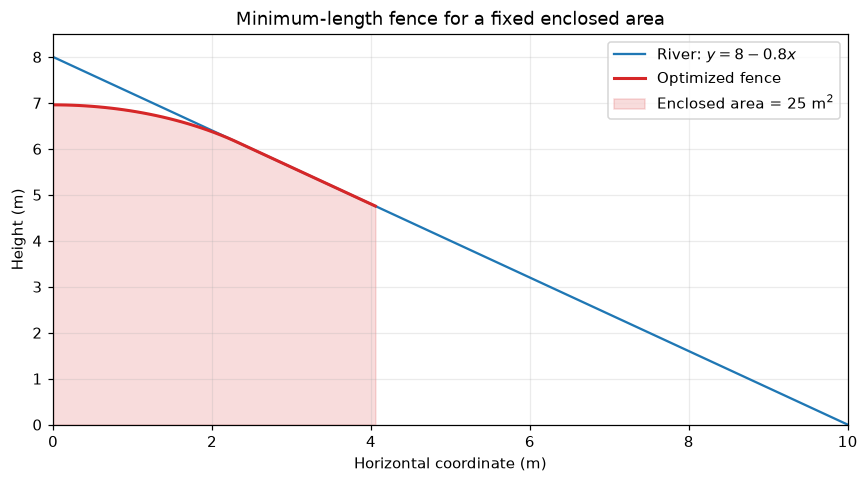

In [5]:
river_x = np.linspace(0.0, 10.0, 300)
river_y = 8.0 - 0.8 * river_x
figure, axes = plt.subplots(figsize=(8, 4.5))
axes.plot(river_x, river_y, color="tab:blue", label=r"River: $y=8-0.8x$")
axes.plot(
    fence_x_coordinates,
    fence_heights,
    color="tab:red",
    linewidth=2,
    label="Optimized fence",
)
axes.fill_between(
    fence_x_coordinates,
    0.0,
    fence_heights,
    color="tab:red",
    alpha=0.16,
    label=f"Enclosed area = {target_area:g} m$^2$",
)
axes.set(
    xlabel="Horizontal coordinate (m)",
    ylabel="Height (m)",
    title="Minimum-length fence for a fixed enclosed area",
    xlim=(0, 10),
    ylim=(0, 8.5),
)
axes.grid(True, alpha=0.25)
axes.legend()
figure.tight_layout()
plt.show()


## Interpretation and further study

The reciprocal objective is strictly convex for positive variables and has a unique minimizer; the three runs should reach the same point. The fence problem is nonlinear and discretized: its result depends on the segment count and the feasibility of the optimizer's returned point. The cell reports area error and river clearance so these conditions can be checked directly.

- Repeat the fence solve for 35 m$^2$ and compare the resulting geometry.
- Increase the segment count and examine changes in fence length and shape.
- Derive the complementary-slackness conditions for the reciprocal objective by hand.